In [ ]:
from data_processing import process_mat_file
from paths import weagets_input, weagets_output, future_climate_dir
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from climate_extreme import ClimateExtreme
import climate_stats as cs
import scipy.stats as stats

from BucketModel import BucketModel, BucketModelOptimizer
from BucketModel.data_processing import (
    preprocess_for_bucket_model,
    run_multiple_simulations,
)
from BucketModel.bucket_model_plotter import *

from climate_simulation import run_model_for_future_climate, plot_climate_scenarios

from uncertainty_analysis import UncertaintyAnalysis, simulate_and_aggregate_streamflows

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

import statsmodels.tsa.api as smt
import statsmodels.api as sm

from generate_future_climate import generate_future_climate

import os


import warnings
warnings.filterwarnings("ignore")

## (WEEK 1) Simulating ensembles with the WeaGETS weather generator.
### Reading in the input data and the output files from WeaGETS

<div style="background-color: #3b1d1d; padding: 12px 16px; border-radius: 6px; border-left: 4px solid #ff7f7f; margin: 10px 0; color: #ffffff; display: inline-block;">
⚠️ <strong>Important:</strong> Store the simulated data (the .mat files) in the <strong>data</strong> folder!
</div>

In [ ]:
STATION = "LATTERBACH"  # GSTEIG, HONDRICH or LATTERBACH
input_data_path = weagets_input(STATION)  # OBSERVATIONS dataset
simulation_path = weagets_output(STATION)  # WeaGETS SIMULATIONS dataset (run_weagets_batch.m)

#Process the MATLAB files to a suitable format
present_data = process_mat_file(input_data_path)
latterbach_out = process_mat_file(simulation_path)


In [3]:
# Inspect the OBSERVATIONS (see the number of datapoints - rows, compare it with the WeaGETS output)
present_data

,Precipitation,T_max,T_min,T_avg,Year,Month,Day
0,8.7,-3.3,-6.7,-5.00,1980,Jan,1
1,4.1,-6.0,-8.9,-7.45,1980,Jan,2
2,0.7,-7.7,-11.9,-9.80,1980,Jan,3
3,7.0,-8.8,-11.4,-10.10,1980,Jan,4
4,4.0,-5.8,-11.5,-8.65,1980,Jan,5
...,...,...,...,...,...,...,...
10945,0.3,-10.5,-15.0,-12.75,2009,Dec,27
10946,3.9,-8.3,-13.5,-10.90,2009,Dec,28
10947,0.6,-10.9,-15.3,-13.10,2009,Dec,29
10948,5.7,-3.2,-19.0,-11.10,2009,Dec,30


In [4]:
# Inspect the WeaGETS SIMULATIONS (notice that you have a "Simulation" column marking the ordinal number of the realisation)
latterbach_out

,Precipitation,T_max,T_min,Year,Simulation,T_avg,Month,Day
0,0.000000,3.578293,-6.655491,1980,1,-1.538599,Jan,1
1,0.000000,-0.355742,-9.670026,1980,1,-5.012884,Jan,2
2,8.130427,-1.376099,-9.714346,1980,1,-5.545223,Jan,3
3,14.594560,-7.503503,-12.414409,1980,1,-9.958956,Jan,4
4,0.000000,-5.319668,-10.645626,1980,1,-7.982647,Jan,5
...,...,...,...,...,...,...,...,...
547495,0.000000,5.367706,-3.555155,2009,50,0.906276,Dec,27
547496,0.000000,2.661103,-4.319788,2009,50,-0.829343,Dec,28
547497,7.750325,-1.691153,-5.581404,2009,50,-3.636279,Dec,29
547498,0.000000,0.976779,-8.522311,2009,50,-3.772766,Dec,30


## Looking at climate statistics to compare generated data to observed data
### Comparing number of wet days (Precipitation > 0.1 mm) in the generated data to the observed data

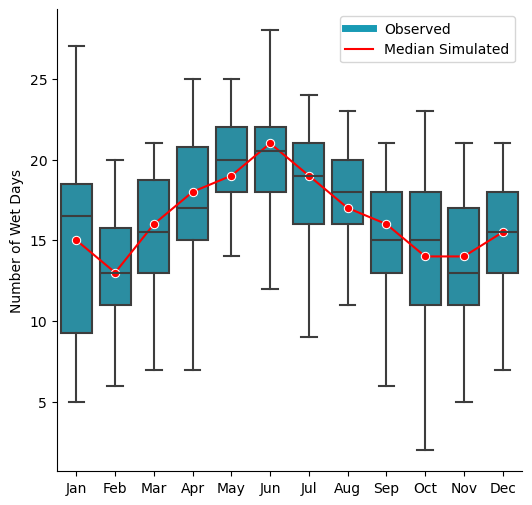

In [5]:
cs.plot_wet_days(
    present_data,
    latterbach_out
) # You can add the output_destination parameter to save the plot

### Comparing the Estimated Cumulative Distribution Function (ECDF) of the two datasets for Precipitation

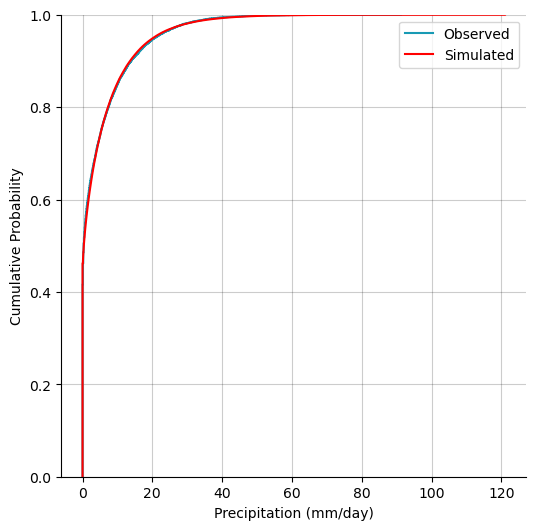

In [6]:
cs.plot_ECDF(
    observations=present_data,
    simulation=latterbach_out,
    column="Precipitation",
    xlabel="Precipitation (mm/day)",
)

### Comparing mean and standard deviation of Average Temperature values

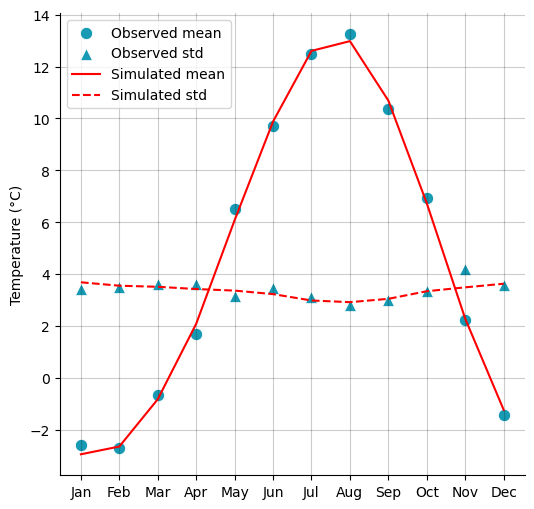

In [7]:
cs.plot_mean_and_std(observations=present_data, simulation=latterbach_out)

### Compare the extreme values - Plot the distributions above a given quantile for visual inspection

In [8]:
# Create instances of ClimateExtreme Class
observed = ClimateExtreme(present_data)
latterbach = ClimateExtreme(latterbach_out)

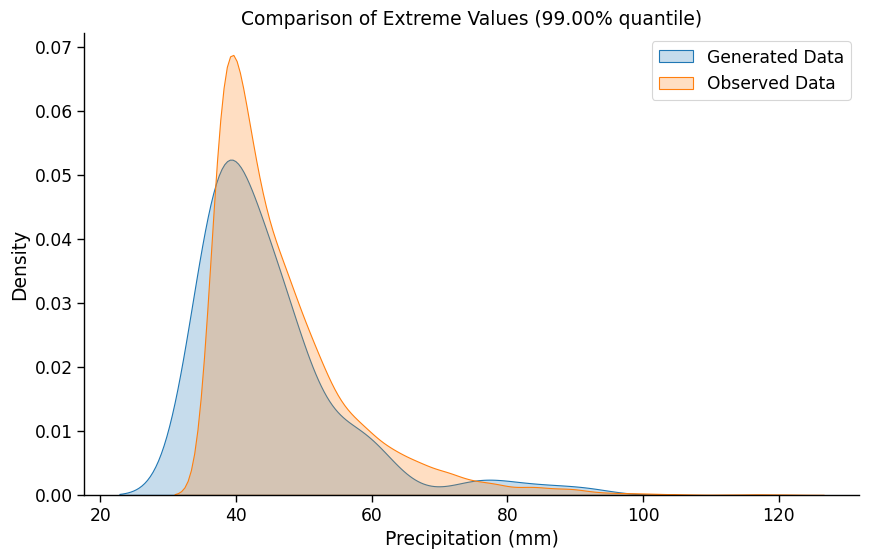

In [9]:
#These plots contain the data points 
observed.plot_extreme_comparison(column="Precipitation", other=latterbach, quantile=0.99, output_destination="", units="mm")

### Perform the KS test for each WeaGETS realisation against the extremes of the observations

KS Tests Completed.


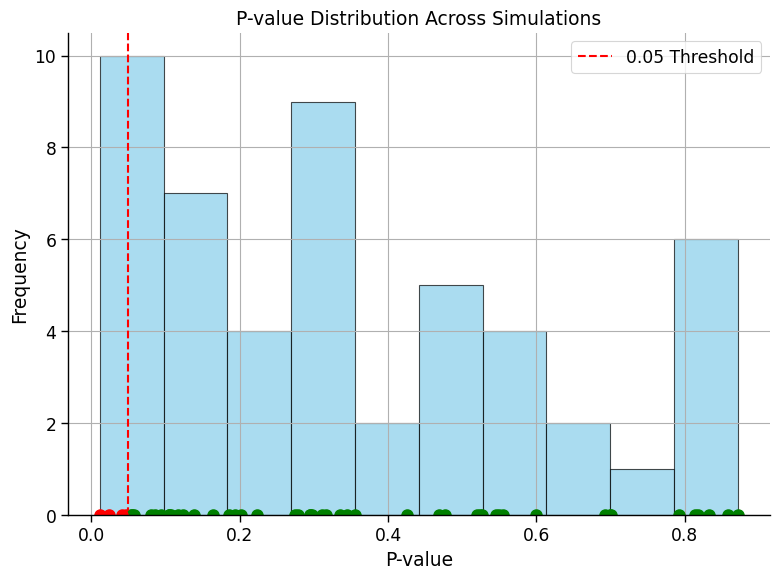

In [10]:
# Call the run_simulation_ks_tests method
ks_results = latterbach.run_simulation_ks_tests(
    observed_data=observed,          # Pass the observed data instance
    column="Precipitation",     # Specify the column to compare
    quantile=0.95               # Specify the quantile for truncation
)

# Output the results
latterbach.plot_ks_results(ks_results)

## Running the Bucket Model
#### Preprocessing the data to match the format required by the Bucket Model


In [11]:
processed_present_data = preprocess_for_bucket_model(present_data)
latterbach_preprocessed = preprocess_for_bucket_model(latterbach_out)


In [12]:
processed_present_data

,P_mix,T_max,T_min
date,,,
1980-01-01,8.7,-3.3,-6.7
1980-01-02,4.1,-6.0,-8.9
1980-01-03,0.7,-7.7,-11.9
1980-01-04,7.0,-8.8,-11.4
1980-01-05,4.0,-5.8,-11.5
...,...,...,...
2009-12-27,0.3,-10.5,-15.0
2009-12-28,3.9,-8.3,-13.5
2009-12-29,0.6,-10.9,-15.3


In [13]:
latterbach_preprocessed

,P_mix,T_max,T_min,Simulation
date,,,,
1980-01-01,0.000000,3.578293,-6.655491,1
1980-01-02,0.000000,-0.355742,-9.670026,1
1980-01-03,8.130427,-1.376099,-9.714346,1
1980-01-04,14.594560,-7.503503,-12.414409,1
1980-01-05,0.000000,-5.319668,-10.645626,1
...,...,...,...,...
2009-12-27,0.000000,5.367706,-3.555155,50
2009-12-28,0.000000,2.661103,-4.319788,50
2009-12-29,7.750325,-1.691153,-5.581404,50


### Setting up the model for the catchment. Here I use the calibrated parameters from Assignment 2

In [14]:
bucket_model = BucketModel(
    k=1.391, S_max=45.666, fr=0.073, rg=25.17, snow_threshold_temp=0.555
)  # Parameters from Assignment 2

bucket_model.set_catchment_properties(
    lapse_rate=0.5 / 100,  # °C/m
    basin_mean_elevation=2035,  # m.a.s.l
    hru_mean_elevation=2035,  # m.a.s.l
    snowmelt_temp_threshold=0,  # °C
    latitude=46.9,  # °N
)

### Running the model for the present data and visualising the results

In [15]:
present_results = bucket_model.run(data=processed_present_data)

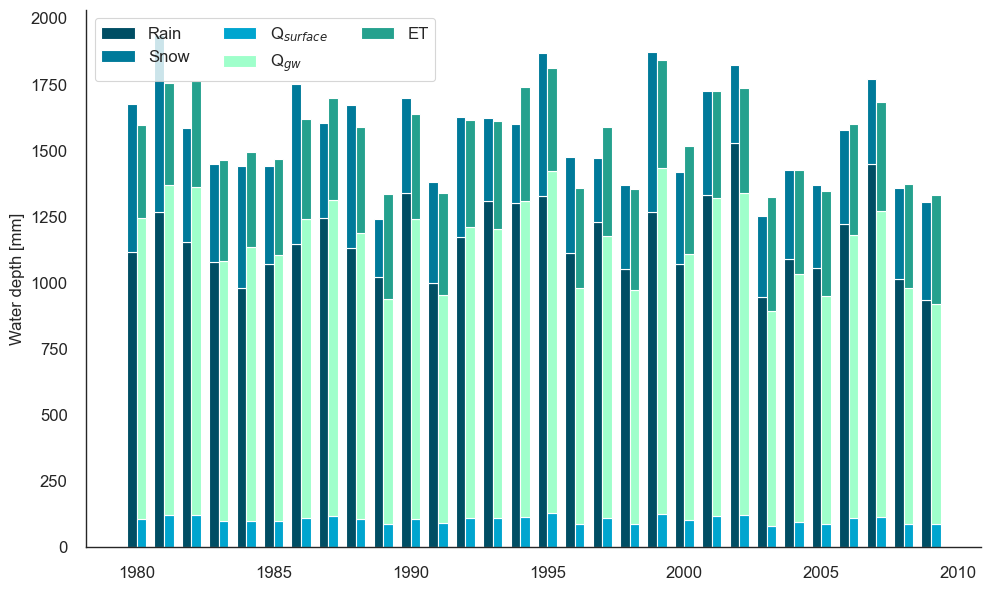

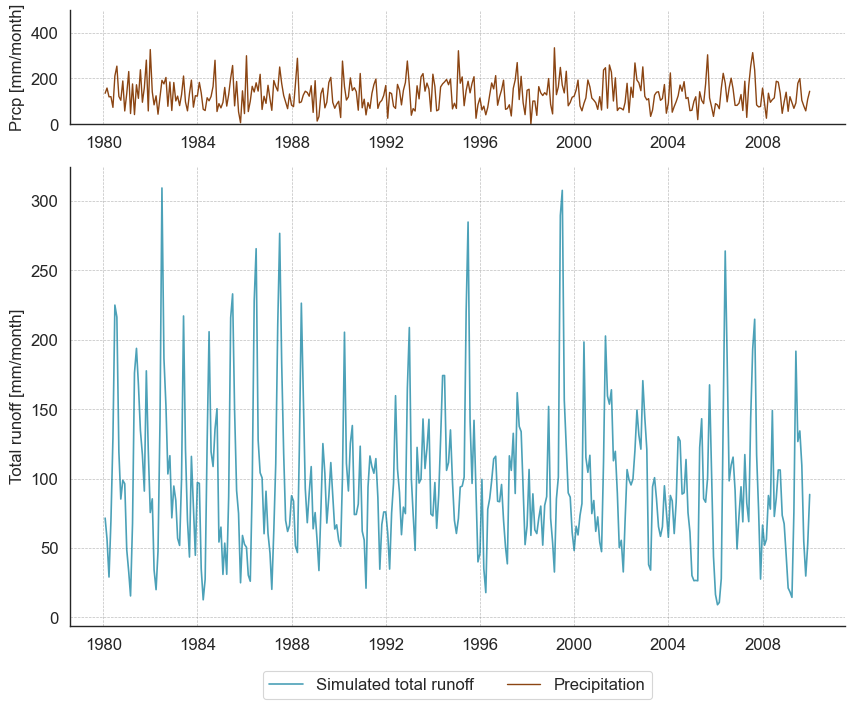

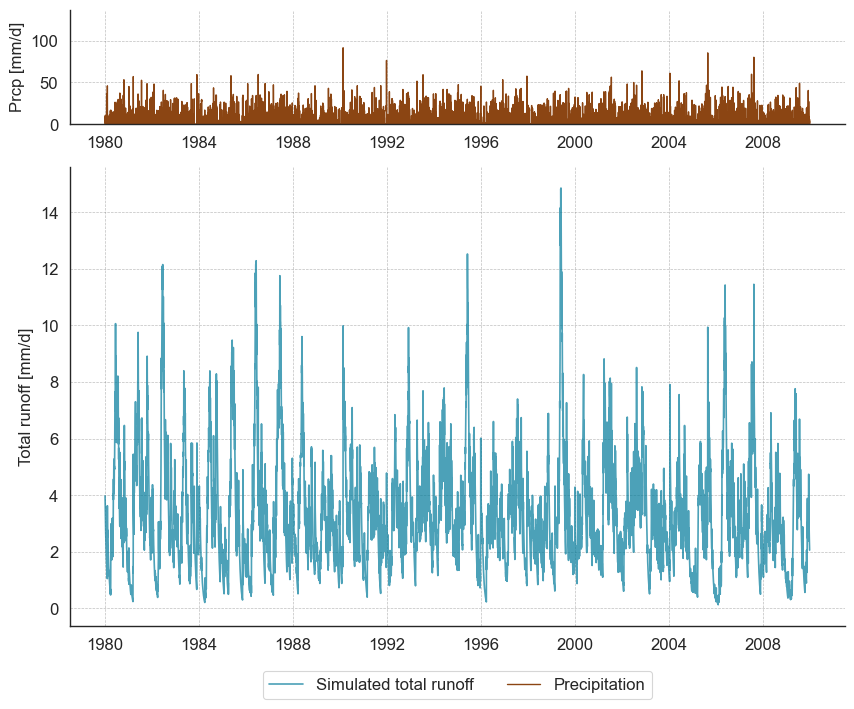

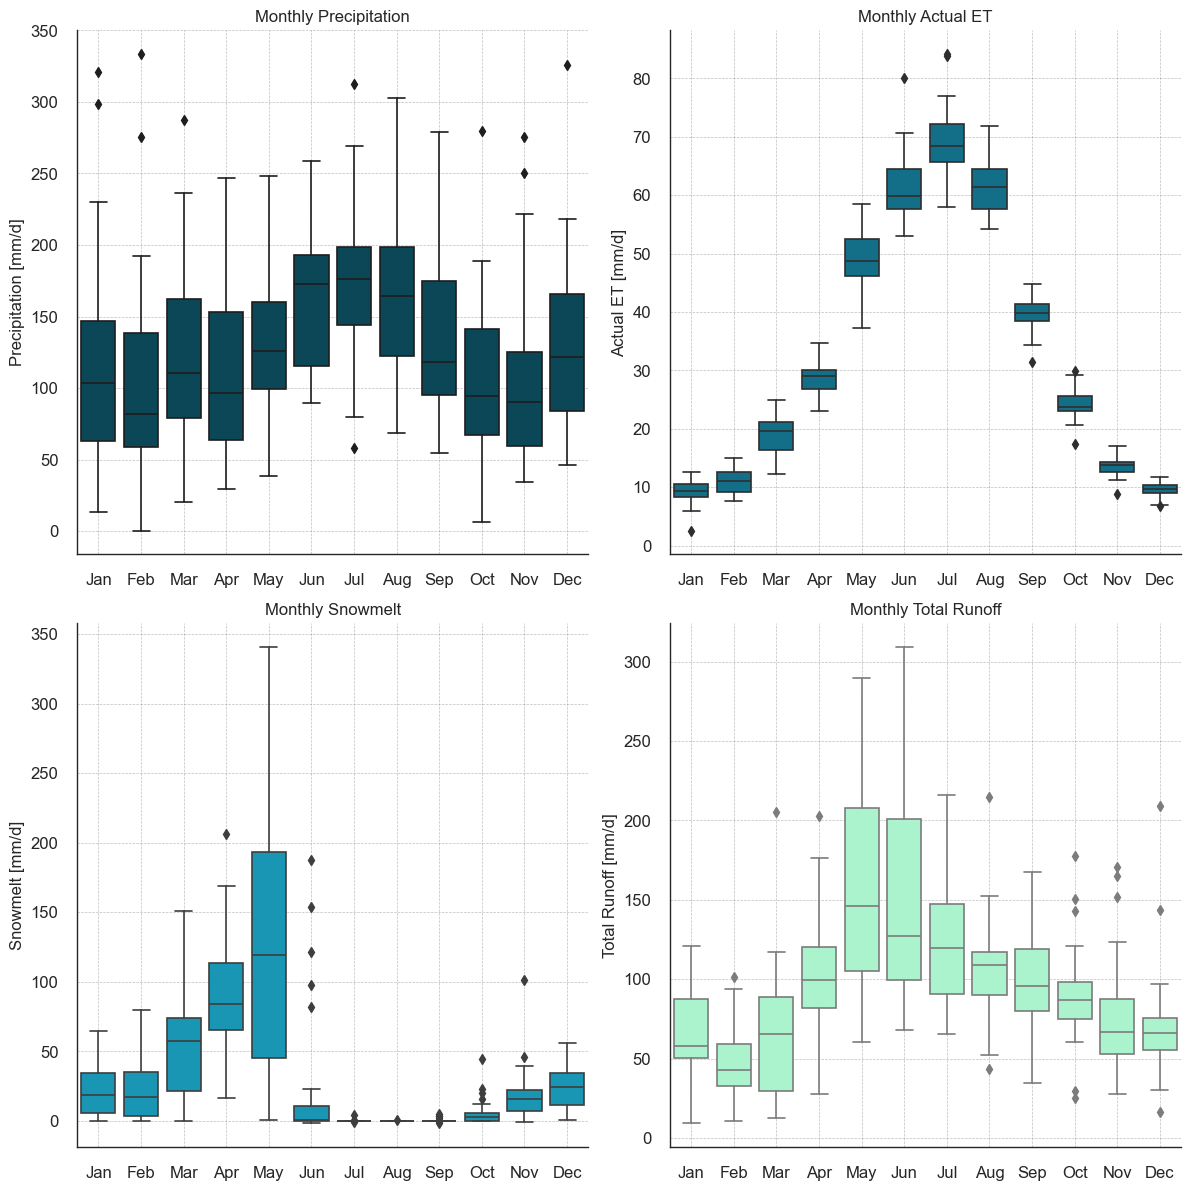

In [16]:
plot_water_balance(results=present_results, start_year="1980", end_year="2010")

plot_timeseries(
    results=present_results,
    start_year="1980",
    end_year="2010",
    monthly=True,
    plot_precipitation=True,
)
plot_timeseries(
    results=present_results,
    start_year="1980",
    end_year="2010",
    monthly=False,
    plot_precipitation=True,
)
plot_monthly_boxplot(results=present_results)

### Run the model for each Simulation individually. Here _Simulation_ refers to the number of 30 years ensembles generated with WeaGETS.

In [17]:
multiple_results = run_multiple_simulations(
    preprocessed_simulated_data=latterbach_preprocessed,
    bucket_model=bucket_model,
    n_simulations=50,
)

In [18]:
multiple_results

,ET,Q_s,Q_gw,Snow_accum,S,S_gw,Snow_melt,Rain,Snow,Precip,Simulation
1980-01-01,0.285111,0.0,1.977637,63.718906,43.556302,47.799494,0.0,0.0,0.000000,0.000000,1
1980-01-02,0.222002,0.0,1.899066,63.718906,43.334300,45.900428,0.0,0.0,0.000000,0.000000,1
1980-01-03,0.213318,0.0,1.823617,71.849333,43.120982,44.076812,0.0,0.0,8.130427,8.130427,1
1980-01-04,0.153729,0.0,1.751165,86.443893,42.967253,42.325647,0.0,0.0,14.594560,14.594560,1
1980-01-05,0.178362,0.0,1.681591,86.443893,42.788891,40.644056,0.0,0.0,0.000000,0.000000,1
...,...,...,...,...,...,...,...,...,...,...,...
2009-12-27,0.347351,0.0,2.791013,0.000000,45.318649,67.458774,0.0,0.0,0.000000,0.000000,50
2009-12-28,0.306347,0.0,2.680126,0.000000,45.012302,64.778647,0.0,0.0,0.000000,0.000000,50
2009-12-29,0.250223,0.0,2.573645,7.750325,44.762079,62.205002,0.0,0.0,7.750325,7.750325,50
2009-12-30,0.247050,0.0,2.471395,7.750325,44.515028,59.733608,0.0,0.0,0.000000,0.000000,50


### Grouping the results by month and computing the 95% confidence interval

,year,ET,Q_s,Q_gw,Snow_accum,S,S_gw,Snow_melt,Rain,Snow,Precip,total_runoff
month,,,,,,,,,,,,
1,1994.5,9.211683,3.719708,53.356726,3411.262206,1367.707181,1330.818135,23.783150,29.527447,88.016754,117.544201,57.076435
2,1994.5,10.932173,3.540638,39.904427,4788.220753,1218.410468,1002.360757,25.183141,26.902954,80.018329,106.921283,43.445066
3,1994.5,18.696605,6.291738,50.671712,6585.730731,1356.209051,1290.823236,51.548166,40.409649,73.583906,113.993555,56.963450
4,1994.5,29.618845,12.488492,86.956542,5959.328837,1344.387627,2234.532568,106.585070,69.020665,47.942324,116.962989,99.445033
5,1994.5,48.538513,18.095241,149.434939,2716.984503,1381.212567,3801.334019,143.844337,111.139042,13.226462,124.365505,167.530180
6,1994.5,63.484663,13.258185,153.847062,225.655428,1287.520356,3843.421647,29.867400,169.361450,1.868235,171.229685,167.105247
7,1994.5,70.969434,11.024195,117.626492,1.836553,1276.797476,2937.882983,0.450938,175.316915,0.061533,175.378448,128.650687
8,1994.5,60.710018,9.800950,94.011086,0.029015,1272.904204,2357.451573,0.009480,157.550565,0.012127,157.562692,103.812037
9,1994.5,41.138971,8.743164,90.858568,1.104967,1271.776388,2278.851985,0.280358,132.195811,0.478141,132.673951,99.601731


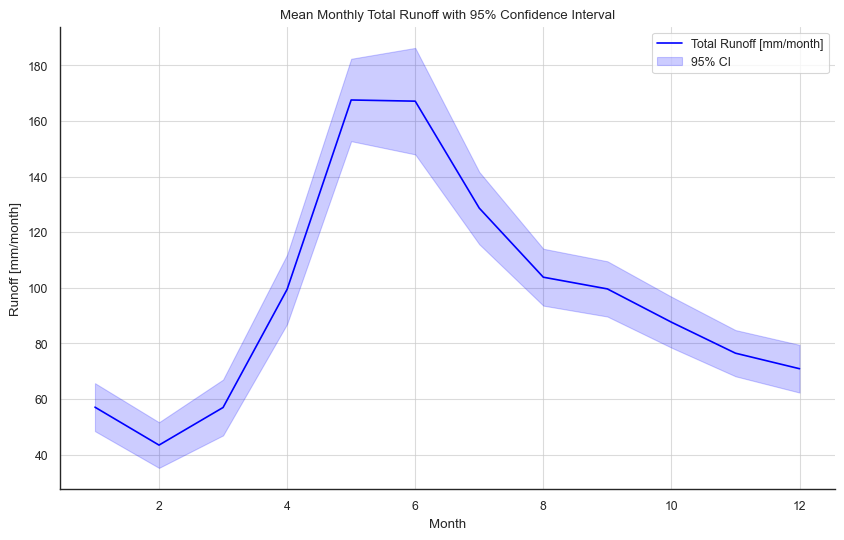

In [19]:
monthly_mean, ci = group_by_month_with_ci(multiple_results)

plot_monthly_runoff_with_ci(monthly_mean, ci)

monthly_mean

# TODO: remove simulation column

## (Week 2) Assessing the changes to streamflow in a future climate
### Generate a future climate ensemble consisting of n multiple realizations (simulations) for 5 climate trajectories (climate models) and 2 different greenhouse gas (GHG) emission scenarios applying the delta-change approach.

In [ ]:
generate_future_climate(
    data=latterbach_out,
    name="exp_first",
    output_folder=future_climate_dir(STATION),
)

### Simulate future streamflow using the future climate ensemble and the Bucket

In [ ]:
future_data_folder = future_climate_dir(STATION)
results = run_model_for_future_climate(
    future_data_folder=future_data_folder,
    bucket_model=bucket_model,
)

# Prepare present data for plotting
present_monthly_mean, _ = group_by_month_with_ci(present_results)
present_monthly_mean['total_runoff'] = present_monthly_mean['Q_s'] + present_monthly_mean['Q_gw']

plot_climate_scenarios(
    results,
    present_results=present_monthly_mean,
) # Again, you can add the output_destination parameter to save the plot

### Simulate future streamflow using the future climate ensemble and the Bucket Model

In [ ]:
folder_path = future_climate_dir(STATION) # Path to the folder containing the future climate scenarios
combined_df = simulate_and_aggregate_streamflows(folder_path, bucket_model, 50)

In [ ]:
combined_df

### Partition the hydrological (streamflow) uncertainties predicted in a future climate into their climatic sources – emission uncertainty, climate model uncertainty, and stochastic uncertainty

In [ ]:
uncertainty = UncertaintyAnalysis(combined_df)

tu = uncertainty.calculate_tu('Streamflow')
eu, eu_partition = uncertainty.calculate_eu('Streamflow', tu)
cmu, cmu_partition = uncertainty.calculate_cmu('Streamflow', tu)
su, su_partition = uncertainty.calculate_su('Streamflow', tu)

print(f"Total Uncertainty: {tu}")
print(f"Emission Scenario Uncertainty: {eu} (Partition: {eu_partition})")
print(f"Climate Model Uncertainty: {cmu} (Partition: {cmu_partition})")
print(f"Stochastic Uncertainty: {su} (Partition: {su_partition})")